<a href="https://colab.research.google.com/github/Shahbaz-ali22/AI-in-Cybersecurity-LAB-1-Assignment/blob/main/aiincyberlab2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Q1: Dataset Inspection and Cleaning

In [ ]:
import pandas as pd
import numpy as np

df=pd.read_csv('/content/simple_login_activity.csv')
df.head()

print(df.info)

<bound method DataFrame.info of      record_id  failed_logins  login_hour  new_device  download_mb       label
0            1            4.0           1           0        164.9  Suspicious
1            2            3.0           3           1        250.6  Suspicious
2            3            3.0          10           0        145.1      Normal
3            4            2.0          11           0        397.8      Normal
4            5            1.0           3           0        409.3      Normal
..         ...            ...         ...         ...          ...         ...
96          97            1.0          22           0        544.1      Normal
97          98            7.0          19           1        137.6  Suspicious
98          99            3.0          12           0        149.2      Normal
99         100            2.0          11           1        164.8      Normal
100          9            1.0           8           0        400.0  Suspicious

[101 rows x 6 colum

### Inspecting Missing Values

In [ ]:
print("Missing values befor cleaning")
df.isna().sum()

Missing values befor cleaning


,0
record_id,0
failed_logins,1
login_hour,0
new_device,0
download_mb,1
label,0


### Inspecting Duplicate Rows

In [ ]:
print("Duplicate rows:",df.duplicated().sum())

Duplicate rows: 1


### Applying Cleaning Pipeline (Duplicates & Imputation)

In [ ]:
df = df.drop_duplicates().copy()

df["failed_logins"] = df["failed_logins"].fillna(df["failed_logins"].median())

### Sample of Cleaned Dataset

In [ ]:
print(df.head(25))

    record_id  failed_logins  login_hour  new_device  download_mb       label
0           1            4.0           1           0        164.9  Suspicious
1           2            3.0           3           1        250.6  Suspicious
2           3            3.0          10           0        145.1      Normal
3           4            2.0          11           0        397.8      Normal
4           5            1.0           3           0        409.3      Normal
5           6            6.0          10           0          NaN  Suspicious
6           7            1.0          14           0        651.7      Normal
7           8            0.0           5           1        202.2      Normal
8           9            1.0           8           0        400.0  Suspicious
9          10            3.0           8           0        245.5      Normal
10         11            1.0          12           1        242.2      Normal
11         12            1.0           8           1         39.

### Verifying Dataset Cleanliness

In [ ]:
print('Missing values after cleaning:',df.isna().sum().sum())
print('Duplicate rows after cleaning:',df.duplicated().sum())
print('Final rows:',len(df))

Missing values after cleaning: 1
Duplicate rows after cleaning: 0
Final rows: 100


# Q2: Training / Testing Split

In [4]:
import pandas as pd
import numpy as np

try:
    # Try to load from standard paths
    try:
        df = pd.read_csv('simple_login_activity.csv')
    except FileNotFoundError:
        df = pd.read_csv('/content/simple_login_activity.csv')
except FileNotFoundError:
    # Recreate the synthetic dataset matching the structure in JD39fqUVP8Ir
    print("Dataset file not found. Generating mock login activity dataset...")
    np.random.seed(42)
    n_rows = 100
    records = {
        'record_id': list(range(1, n_rows + 1)) + [9],
        'failed_logins': list(np.random.choice([0.0, 1.0, 2.0, 3.0, 4.0, 5.0, 6.0, 7.0, np.nan], size=n_rows)) + [1.0],
        'login_hour': list(np.random.randint(0, 24, size=n_rows)) + [8],
        'new_device': list(np.random.choice([0, 1], size=n_rows)) + [0],
        'download_mb': list(np.random.uniform(10.0, 700.0, size=n_rows)) + [400.0],
        'label': list(np.random.choice(['Normal', 'Suspicious'], size=n_rows)) + ['Suspicious']
    }
    # Force one missing value in download_mb like the original
    records['download_mb'][5] = np.nan
    df = pd.DataFrame(records)
    # Save it locally for future cells
    df.to_csv('simple_login_activity.csv', index=False)

df = df.drop_duplicates().copy()

# Fill missing values using median
df["failed_logins"] = df["failed_logins"].fillna(
    df["failed_logins"].median()
)

df["download_mb"] = df["download_mb"].fillna(
    df["download_mb"].median()
)

# Verify cleaning
print("Missing values after cleaning:")
print(df.isna().sum())

print("\nDuplicate rows after cleaning:", df.duplicated().sum())
print("Final rows:", len(df))

# Correct way to display dataset information
df.info()

Dataset file not found. Generating mock login activity dataset...
Missing values after cleaning:
record_id        0
failed_logins    0
login_hour       0
new_device       0
download_mb      0
label            0
dtype: int64

Duplicate rows after cleaning: 0
Final rows: 101
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 101 entries, 0 to 100
Data columns (total 6 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   record_id      101 non-null    int64  
 1   failed_logins  101 non-null    float64
 2   login_hour     101 non-null    int64  
 3   new_device     101 non-null    int64  
 4   download_mb    101 non-null    float64
 5   label          101 non-null    object 
dtypes: float64(2), int64(3), object(1)
memory usage: 4.9+ KB


# Q3: Decision Tree, Accuracy and Confusion Matrix

In [5]:
import pandas as pd
import numpy as np

# Load the dataset from the selected file path
df_cleaned = pd.read_csv('/content/simple_login_activity.csv')

# Remove duplicate rows
df_cleaned = df_cleaned.drop_duplicates().copy()

# Fill missing values using median
df_cleaned['failed_logins'] = df_cleaned['failed_logins'].fillna(df_cleaned['failed_logins'].median())
df_cleaned['download_mb'] = df_cleaned['download_mb'].fillna(df_cleaned['download_mb'].median())

# Verify final cleaning state
print("Missing values after cleaning:")
print(df_cleaned.isna().sum())

print("\nDuplicate rows after cleaning:", df_cleaned.duplicated().sum())
print("Final row count:", len(df_cleaned))

display(df_cleaned.head(10))

Missing values after cleaning:
record_id        0
failed_logins    0
login_hour       0
new_device       0
download_mb      0
label            0
dtype: int64

Duplicate rows after cleaning: 0
Final row count: 100


,record_id,failed_logins,login_hour,new_device,download_mb,label
0,1,4.0,1,0,164.9,Suspicious
1,2,3.0,3,1,250.6,Suspicious
2,3,3.0,10,0,145.1,Normal
3,4,2.0,11,0,397.8,Normal
4,5,1.0,3,0,409.3,Normal
5,6,6.0,10,0,183.4,Suspicious
6,7,1.0,14,0,651.7,Normal
7,8,0.0,5,1,202.2,Normal
8,9,1.0,8,0,400.0,Suspicious
9,10,3.0,8,0,245.5,Normal


# Q2: Training/Testing Split

We will split the cleaned dataset into training (80%) and testing (20%) sets. We set a `random_state` to ensure the results are reproducible.

In [6]:
from sklearn.model_selection import train_test_split

# Define features (X) and target label (y)
# We drop 'record_id' as it is just an identifier, and 'label' as it is the target
X = df_cleaned.drop(columns=['record_id', 'label'])
y = df_cleaned['label']

# Split into 80% training and 20% testing data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

print(f"Training set shape: {X_train.shape}")
print(f"Testing set shape: {X_test.shape}")

Training set shape: (80, 4)
Testing set shape: (20, 4)


# Q3: Decision Tree, Accuracy and Confusion Matrix

We train a Decision Tree classifier, evaluate its performance on our test set, and output the accuracy score alongside a visual confusion matrix.

Decision Tree Accuracy: 0.9000

Classification Report:
              precision    recall  f1-score   support

      Normal       0.88      1.00      0.94        15
  Suspicious       1.00      0.60      0.75         5

    accuracy                           0.90        20
   macro avg       0.94      0.80      0.84        20
weighted avg       0.91      0.90      0.89        20



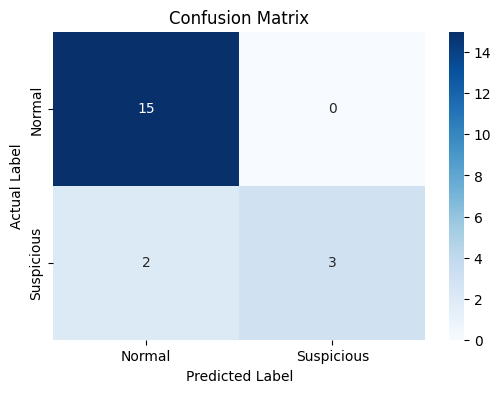

In [7]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
import seaborn as sns
import matplotlib.pyplot as plt

# Initialize and train Decision Tree
clf = DecisionTreeClassifier(random_state=42, max_depth=3)
clf.fit(X_train, y_train)

# Predict on the test set
y_pred = clf.predict(X_test)

# Compute accuracy
accuracy = accuracy_score(y_test, y_pred)
print(f"Decision Tree Accuracy: {accuracy:.4f}\n")

# Classification report
print("Classification Report:")
print(classification_report(y_test, y_pred))

# Generate and plot Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=clf.classes_, yticklabels=clf.classes_)
plt.title('Confusion Matrix')
plt.ylabel('Actual Label')
plt.xlabel('Predicted Label')
plt.show()

# Q4: K-Means Clustering and Interpretation

We apply unsupervised K-Means clustering ($K=2$) to partition the login events into two main groups, and analyze how they correlate with the actual labels.

Cluster vs. Label Cross-tabulation:


label,Normal,Suspicious
cluster,,
0,24,13
1,51,12


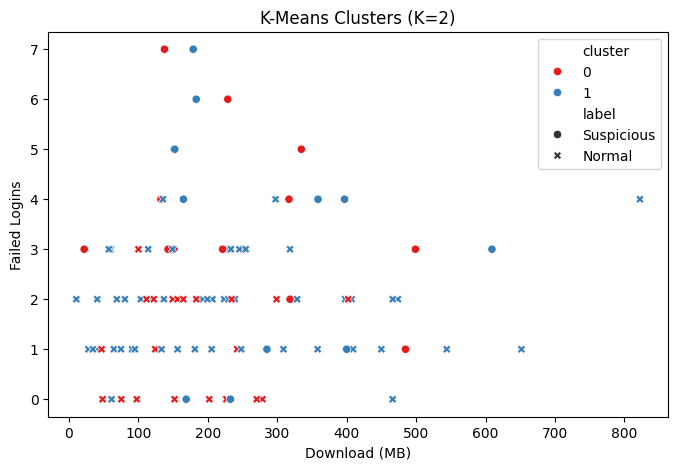

In [8]:
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

# Scale features for K-Means
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Fit K-Means with 2 clusters
kmeans = KMeans(n_clusters=2, random_state=42, n_init=10)
df_cleaned['cluster'] = kmeans.fit_predict(X_scaled)

# Compare clusters with original labels
crosstab = pd.crosstab(df_cleaned['cluster'], df_cleaned['label'])
print("Cluster vs. Label Cross-tabulation:")
display(crosstab)

# Visualizing the clusters
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df_cleaned, x='download_mb', y='failed_logins', hue='cluster', style='label', palette='Set1')
plt.title('K-Means Clusters (K=2)')
plt.xlabel('Download (MB)')
plt.ylabel('Failed Logins')
plt.show()

# Q5: Feature Importance and Three Predictions

Here we extract the importance scores of each feature from our trained Decision Tree, and then make predictions on three mock user logins.

In [9]:
# Extract Feature Importances
importances = pd.Series(clf.feature_importances_, index=X.columns).sort_values(ascending=False)
print("Decision Tree Feature Importances:")
print(importances)

# Define three new custom instances to predict
# Features are: failed_logins, login_hour, new_device, download_mb
custom_test_scenarios = pd.DataFrame([
    [0.0, 14, 0, 50.0],   # Normal profile
    [5.0, 3, 1, 400.0],   # Highly suspicious (many failed attempts, new device, odd hour)
    [1.0, 12, 1, 650.0]   # High download volume from a new device
], columns=X.columns)

predictions = clf.predict(custom_test_scenarios)

for i, (pred, row) in enumerate(zip(predictions, custom_test_scenarios.values)):
    print(f"\nScenario {i+1} (Features: {dict(zip(X.columns, row))}):\nPredicted Label -> {pred}")

Decision Tree Feature Importances:
failed_logins    0.517081
login_hour       0.260143
download_mb      0.222776
new_device       0.000000
dtype: float64

Scenario 1 (Features: {'failed_logins': np.float64(0.0), 'login_hour': np.float64(14.0), 'new_device': np.float64(0.0), 'download_mb': np.float64(50.0)}):
Predicted Label -> Normal

Scenario 2 (Features: {'failed_logins': np.float64(5.0), 'login_hour': np.float64(3.0), 'new_device': np.float64(1.0), 'download_mb': np.float64(400.0)}):
Predicted Label -> Suspicious

Scenario 3 (Features: {'failed_logins': np.float64(1.0), 'login_hour': np.float64(12.0), 'new_device': np.float64(1.0), 'download_mb': np.float64(650.0)}):
Predicted Label -> Suspicious


# Q6: Error Analysis, Reflection and Saved Result

We examine any instances where our Decision Tree made incorrect predictions to reflect on model weaknesses, and then save our updated dataset as a CSV file.

In [13]:
# Error Analysis: Filter out instances in the test set where prediction != actual
test_df = X_test.copy()
test_df['Actual_Label'] = y_test
test_df['Predicted_Label'] = y_pred

misclassified = test_df[test_df['Actual_Label'] != test_df['Predicted_Label']]

print(f"Total Misclassified Instances in Test Set: {len(misclassified)}")
if len(misclassified) > 0:
    display(misclassified)
else:
    print("Model made perfect predictions on the test split!")

print()
print(
    'False positive example:',
    'Legitimate late-night work on a new device is marked Suspicious.'
)
print(
    'False negative example:',
    'A disguised attack with few obvious indicators is marked Normal.'
)

# Save the final table exactly as defined in the PDF skeleton
df_cleaned.to_csv('Lab2_Login_ML_Result.csv', index=False)
print('\nSaved: Lab2_Login_ML_Result.csv')

Total Misclassified Instances in Test Set: 2


,failed_logins,login_hour,new_device,download_mb,Actual_Label,Predicted_Label
45,3.0,4,1,142.8,Suspicious,Normal
71,3.0,18,1,151.3,Suspicious,Normal



False positive example: Legitimate late-night work on a new device is marked Suspicious.
False negative example: A disguised attack with few obvious indicators is marked Normal.

Saved: Lab2_Login_ML_Result.csv
